# 1. Analyse des crédits aux entreprises en France

## 1.1. Objectifs de l'analyse

Après avoir exploré et préparé le jeu de données, cette étape consiste à analyser l'évolution des crédits mobilisés par les entreprises en France.

L'objectif est de comprendre les dynamiques de financement des entreprises sur la période allant de janvier 2006 à août 2026, en mettant l'accent sur les différences entre les catégories d'entreprises selon leur ancienneté et leur taille.

Cette analyse vise notamment à répondre aux questions suivantes :

- Comment les encours de crédits mobilisés ont-ils évolué au cours de la période étudiée ?
- Quelles catégories d'entreprises présentent les encours les plus importants ?
- Observe-t-on des différences de dynamique entre les entreprises de plus ou de moins de trois ans ?
- Les PME suivent-elles une évolution comparable à celle de l'ensemble des entreprises ?

Pour répondre à ces questions, l'analyse s'appuiera sur des indicateurs statistiques, des calculs d'évolution et des visualisations afin de dégager les principales tendances observées dans les données.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/raw/credits_entreprises.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    low_memory=False
)


df_analyse = df[
    (df["REF_AREA"] == "FR") &
    (df["DIREN_NATURE"] == "UL") &
    (df["DIREN_OBJET"] == "ME") &
    (df["DIREN_MESURE"] == 1) &
    (df["ADJUSTMENT"] == "N") &
    (df["UNIT"] == "EUR")
].copy()

print("Dimensions :", df_analyse.shape)
print("Nombre de séries :", df_analyse["series_key"].nunique())
print("\nUnités :", df_analyse["UNIT"].value_counts())
print("\nSecteurs :", df_analyse["DIREN_SECTACT"].value_counts())
print("\nTailles :", df_analyse["DIREN_TAILLENT"].value_counts())

In [ ]:
# Nombre d'observations pour chaque combinaison secteur / taille
repartition = df_analyse.groupby(
    ["DIREN_SECTACT", "DIREN_TAILLENT"]
).size().unstack(fill_value=0)

print(repartition)

series_analyse = df_analyse[
    ["series_key", "title_long_fr"]
].drop_duplicates()

print(series_analyse.to_string(index=False))

In [ ]:
df_global = df_analyse[
    (df_analyse["DIREN_SECTACT"] == "ZZ") &
    (df_analyse["DIREN_TAILLENT"] == "TT")
].copy()

print(df_global.shape)

# Convertir la colonne en véritable format date
df_global["time_period"] = pd.to_datetime(
    df_global["time_period"],
    format="%Y-%m"
)

# Trier les observations de la plus ancienne à la plus récente
df_global = df_global.sort_values("time_period").reset_index(drop=True)

# Vérifier le résultat
print(df_global[["time_period", "obs_value"]].head())
print(df_global[["time_period", "obs_value"]].tail())

print("Première date :", df_global["time_period"].min())
print("Dernière date :", df_global["time_period"].max())

print("Valeurs manquantes :", df_global["obs_value"].isna().sum())

print("Statistiques descriptives :")
print(df_global["obs_value"].describe())

In [ ]:
# Identifier précisément la série sélectionnée
print(df_global[["series_key", "title_long_fr"]].drop_duplicates())

# Vérifier la période disponible pour chaque série du périmètre filtré
periodes = df_analyse.groupby("series_key")["time_period"].agg(
    premiere_date="min",
    derniere_date="max",
    nombre_observations="count"
)

print(periodes.sort_values("derniere_date"))

In [ ]:
df_tailles = df_analyse[
    (df_analyse["DIREN_SECTACT"] == "ZZ") &
    (df_analyse["DIREN_TAILLENT"].isin(["EA", "EJ", "PA", "PJ"]))
].copy()

# Convertir les dates
df_tailles["time_period"] = pd.to_datetime(
    df_tailles["time_period"],
    format="%Y-%m"
)

# Trier les données
df_tailles = df_tailles.sort_values("time_period")

# Vérifier les séries disponibles
print(df_tailles.groupby("DIREN_TAILLENT").agg(
    premiere_date=("time_period", "min"),
    derniere_date=("time_period", "max"),
    observations=("obs_value", "count")
))

# Vérifier les valeurs manquantes par catégorie
print(
    df_tailles.groupby("DIREN_TAILLENT")["obs_value"]
    .agg(
        valeurs_non_manquantes="count",
        total="size"
    )
)

# Comparer les encours au début et à la fin de la période
comparaison = df_tailles.groupby("DIREN_TAILLENT").agg(
    premier_encours=("obs_value", "first"),
    dernier_encours=("obs_value", "last")
)

print(comparaison)

In [ ]:
# S'assurer que chaque série est dans l'ordre chronologique
df_tailles = df_tailles.sort_values(
    ["DIREN_TAILLENT", "time_period"]
)

# Récupérer le premier et le dernier encours
evolution = df_tailles.groupby("DIREN_TAILLENT").agg(
    encours_initial=("obs_value", "first"),
    encours_final=("obs_value", "last")
)

# Calculer la variation absolue
evolution["variation_absolue"] = (
    evolution["encours_final"] - evolution["encours_initial"]
)

# Calculer le taux d'évolution en pourcentage
evolution["evolution_pct"] = (
    evolution["variation_absolue"] / evolution["encours_initial"]
) * 100

print(evolution.round(2))

In [ ]:
print("Unités :", df_tailles["UNIT"].unique())
print("Multiplicateurs :", df_tailles["UNIT_MULT"].value_counts())

In [ ]:
# Créer une copie pour la visualisation
df_visualisation = df_tailles.copy()

# Convertir les montants en milliards d'euros
df_visualisation["encours_milliards"] = (
    df_visualisation["obs_value"] / 1000
)

# Associer un nom compréhensible à chaque catégorie
noms_categories = {
    "EA": "Entreprises de plus de 3 ans",
    "EJ": "Entreprises de moins de 3 ans",
    "PA": "PME de plus de 3 ans",
    "PJ": "PME de moins de 3 ans"
}

df_visualisation["categorie"] = (
    df_visualisation["DIREN_TAILLENT"].map(noms_categories)
)

print(df_visualisation[
    ["time_period", "categorie", "encours_milliards"]
].head())

## 1.2. Évolution des encours de crédits

Après avoir défini le périmètre de l'analyse et préparé les données, l'objectif est d'étudier l'évolution des encours de crédits mobilisés entre janvier 2006 et août 2026.

Pour faciliter la comparaison, les montants ont été convertis en milliards d'euros. Les données sont ensuite représentées sous forme de courbes afin de visualiser leur évolution dans le temps pour chacune des quatre catégories d'entreprises étudiées.

Cette visualisation permet notamment de comparer les niveaux d'encours, d'observer les tendances générales et d'identifier d'éventuelles périodes de variation importante.

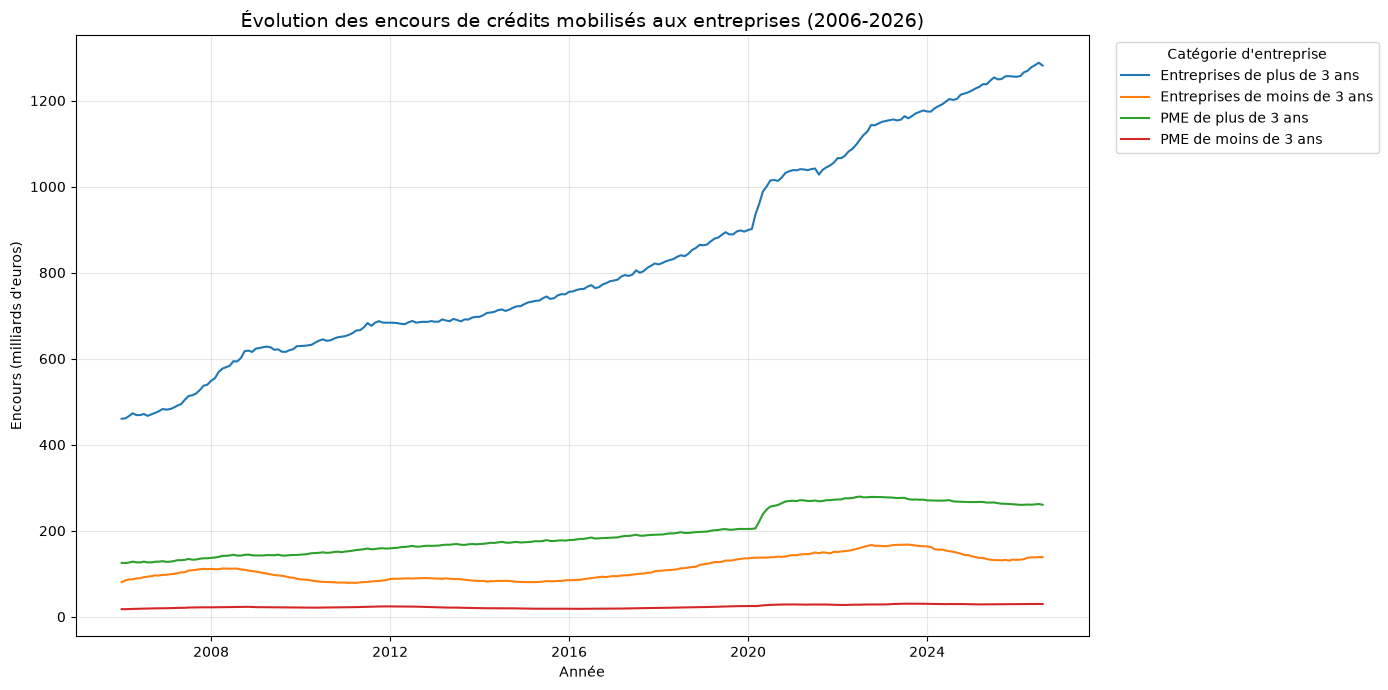

In [20]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_visualisation,
    x="time_period",
    y="encours_milliards",
    hue="categorie"
)

plt.title(
    "Évolution des encours de crédits mobilisés aux entreprises (2006-2026)",
    fontsize=14
)

plt.xlabel("Année")
plt.ylabel("Encours (milliards d'euros)")

plt.legend(
    title="Catégorie d'entreprise",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## 1.3. Interprétation du graphique

La visualisation met en évidence plusieurs tendances dans l'évolution des encours de crédits mobilisés entre 2006 et 2026.

- **Niveau des encours :** les entreprises de plus de 3 ans présentent les encours les plus élevés sur toute la période. Elles sont suivies par les PME de plus de 3 ans.
- **Tendance générale :** les quatre catégories affichent une évolution globalement à la hausse, malgré des rythmes de progression différents.
- **Comparaison entre les catégories :** les encours des entreprises de plus de 3 ans sont nettement supérieurs à ceux des entreprises de moins de 3 ans. Une différence similaire est observable entre les PME selon leur ancienneté.
- **Limites de l'interprétation :** les montants représentent des encours en valeur nominale. Ils ne tiennent donc pas compte de l'inflation. De plus, les PME étant incluses dans l'ensemble des entreprises, les deux populations se recoupent.

Cette première visualisation permet de comparer les niveaux d'encours et leur évolution générale. Une analyse des variations annuelles sera nécessaire pour identifier plus précisément les périodes de croissance et de recul.

## 1.4. Analyse de la croissance annuelle des encours

Après avoir étudié l'évolution des montants des encours de crédits, cette partie vise à analyser leur rythme de croissance au fil du temps.

Pour cela, nous allons calculer le taux de variation annuel (en %) de chaque catégorie d'entreprises, en comparant chaque mois avec le même mois de l'année précédente.

Cette approche permettra :
- D'identifier les périodes de croissance et de recul des encours.
- De repérer les éventuelles accélérations ou ralentissements.
- De comparer les dynamiques de croissance entre les quatre catégories d'entreprises.

L'objectif est ainsi de mieux comprendre les évolutions du financement des entreprises au-delà des seuls montants observés.

In [21]:
# Trier les données par catégorie et par date
df_tailles = df_tailles.sort_values(
    ["DIREN_TAILLENT", "time_period"]
).copy()

# Calculer la croissance par rapport au même mois de l'année précédente
df_tailles["croissance_annuelle_pct"] = (
    df_tailles.groupby("DIREN_TAILLENT")["obs_value"]
    .pct_change(periods=12) * 100
)

# Afficher les résultats
df_tailles[
    ["time_period", "DIREN_TAILLENT", "obs_value", "croissance_annuelle_pct"]
].head(20)

,time_period,DIREN_TAILLENT,obs_value,croissance_annuelle_pct
44575,2006-01-01,EA,460357.0,NaN
44448,2006-02-01,EA,461363.0,NaN
44234,2006-03-01,EA,466507.0,NaN
44083,2006-04-01,EA,473121.0,NaN
44016,2006-05-01,EA,468870.0,NaN
43842,2006-06-01,EA,468896.0,NaN
43699,2006-07-01,EA,471373.0,NaN
43597,2006-08-01,EA,467067.0,NaN
43346,2006-09-01,EA,470615.0,NaN
43199,2006-10-01,EA,473959.0,NaN


## 1.5. Visualisation de la croissance annuelle

Après avoir calculé les taux de croissance annuels, cette visualisation permet d'observer les variations des encours de crédits par catégorie d'entreprises.

Contrairement au graphique précédent, qui présentait les montants des encours, celui-ci met l'accent sur leur rythme de progression.

Il permettra notamment d'identifier les périodes de croissance, de ralentissement et de recul, ainsi que de comparer les dynamiques entre les différentes catégories.

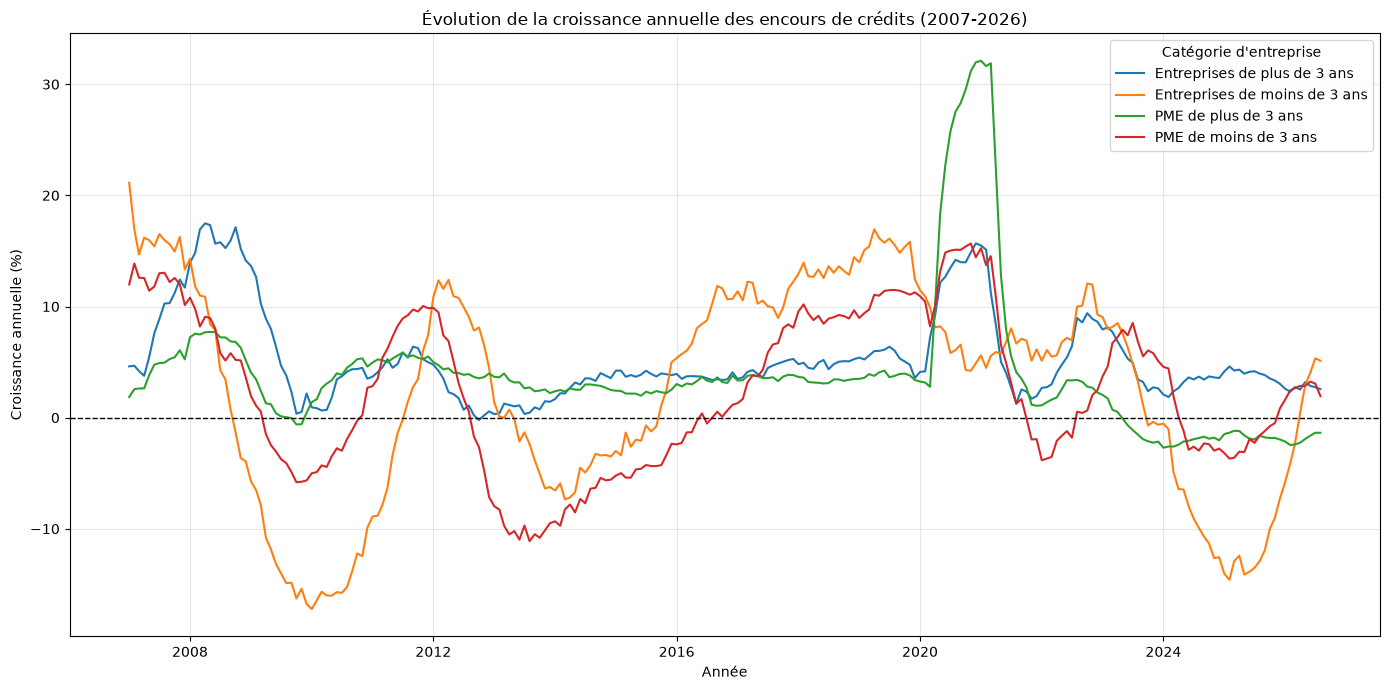

In [23]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_tailles.dropna(subset=["croissance_annuelle_pct"]),
    x="time_period",
    y="croissance_annuelle_pct",
    hue="DIREN_TAILLENT"
)

plt.axhline(y=0, color="black", linestyle="--", linewidth=1)

plt.title("Évolution de la croissance annuelle des encours de crédits (2007-2026)")
plt.xlabel("Année")
plt.ylabel("Croissance annuelle (%)")

# Remplacer les codes par des noms compréhensibles
noms_categories = {
    "EA": "Entreprises de plus de 3 ans",
    "EJ": "Entreprises de moins de 3 ans",
    "PA": "PME de plus de 3 ans",
    "PJ": "PME de moins de 3 ans"
}

plt.legend(
    handles=plt.gca().get_legend_handles_labels()[0],
    labels=[noms_categories[code] for code in ["EA", "EJ", "PA", "PJ"]],
    title="Catégorie d'entreprise"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 1.6. Interprétation de la croissance annuelle

La comparaison des taux de croissance annuels met en évidence des dynamiques différentes selon les catégories d'entreprises.

Les entreprises de plus de 3 ans présentent une évolution relativement régulière sur une grande partie de la période, tandis que les entreprises de moins de 3 ans connaissent des fluctuations plus importantes.

Du côté des PME, les deux catégories présentent également des variations significatives. Une hausse particulièrement marquée apparaît pour les PME de plus de 3 ans autour de 2020-2021.

Ces observations montrent que les dynamiques de croissance des encours ne sont pas identiques selon l'ancienneté et la taille des entreprises.

**Point de vigilance :** les variations les plus importantes devront être examinées plus en détail afin de distinguer les évolutions économiques réelles des éventuels effets statistiques ou changements dans les séries.

## 1.7. Identification des variations annuelles extrêmes

Afin d'approfondir l'analyse, nous allons identifier les périodes durant lesquelles chaque catégorie d'entreprises a enregistré sa croissance annuelle la plus élevée et la plus faible.

Cette analyse permettra de :
- Repérer les périodes de plus forte croissance des encours.
- Identifier les périodes de recul le plus important.
- Comparer les variations extrêmes entre les différentes catégories.

Les résultats seront présentés sous forme de tableau afin de faciliter leur comparaison.

In [24]:
# Exclure les lignes sans taux de croissance calculable
df_croissance = df_tailles.dropna(
    subset=["croissance_annuelle_pct"]
).copy()

# Identifier les indices des croissances maximales et minimales
indices_max = df_croissance.groupby(
    "DIREN_TAILLENT"
)["croissance_annuelle_pct"].idxmax()

indices_min = df_croissance.groupby(
    "DIREN_TAILLENT"
)["croissance_annuelle_pct"].idxmin()

# Récupérer les lignes correspondantes
croissances_max = df_croissance.loc[indices_max].copy()
croissances_min = df_croissance.loc[indices_min].copy()

# Ajouter une colonne pour distinguer les deux types de variations
croissances_max["type_variation"] = "Croissance maximale"
croissances_min["type_variation"] = "Croissance minimale"

# Regrouper les résultats dans un seul tableau
resultats_extremes = pd.concat(
    [croissances_max, croissances_min]
)

# Remplacer les codes par des noms compréhensibles
resultats_extremes["categorie"] = (
    resultats_extremes["DIREN_TAILLENT"].map(noms_categories)
)

# Afficher les résultats
resultats_extremes[
    [
        "categorie",
        "type_variation",
        "time_period",
        "croissance_annuelle_pct"
    ]
].sort_values(
    ["categorie", "type_variation"]
).round(2).reset_index(drop=True)

/var/folders/4j/7nnf7vdd1s5_lp_vs1m28_t80000gn/T/ipykernel_5921/2944500731.py:43: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(2).reset_index(drop=True)


,categorie,type_variation,time_period,croissance_annuelle_pct
0,Entreprises de moins de 3 ans,Croissance maximale,2007-01-01,21.14
1,Entreprises de moins de 3 ans,Croissance minimale,2010-01-01,-17.23
2,Entreprises de plus de 3 ans,Croissance maximale,2008-04-01,17.48
3,Entreprises de plus de 3 ans,Croissance minimale,2012-10-01,-0.21
4,PME de moins de 3 ans,Croissance maximale,2020-11-01,15.67
5,PME de moins de 3 ans,Croissance minimale,2013-08-01,-11.11
6,PME de plus de 3 ans,Croissance maximale,2021-01-01,32.11
7,PME de plus de 3 ans,Croissance minimale,2024-01-01,-2.70


### Interprétation des variations extrêmes

L'analyse des variations annuelles met en évidence des différences importantes entre les catégories d'entreprises.

Les entreprises de moins de 3 ans présentent les fluctuations les plus marquées, avec une croissance maximale de 21,14 % en janvier 2007 et une baisse maximale de 17,23 % en janvier 2010.

À l'inverse, les entreprises de plus de 3 ans affichent une évolution relativement stable, leur plus forte baisse annuelle étant limitée à 0,21 % en octobre 2012.

Un résultat particulièrement notable concerne les PME de plus de 3 ans, dont les encours enregistrent une croissance annuelle maximale de 32,11 % en janvier 2021. Cette variation mérite une analyse complémentaire afin d'en comprendre l'origine.

Enfin, les PME de moins de 3 ans atteignent leur croissance maximale en novembre 2020 (+15,67 %) et leur baisse la plus importante en août 2013 (-11,11 %).

Ces résultats suggèrent que l'ancienneté et la taille des entreprises peuvent être associées à des dynamiques de financement différentes. Toutefois, ces observations ne permettent pas, à elles seules, d'établir un lien de causalité.

In [25]:
# Examiner les encours et leur croissance autour de janvier 2021
df_tailles[
    (df_tailles["DIREN_TAILLENT"] == "PA") &
    (df_tailles["time_period"].between("2020-07-01", "2021-07-01"))
][
    ["time_period", "obs_value", "croissance_annuelle_pct"]
].round(2)

/var/folders/4j/7nnf7vdd1s5_lp_vs1m28_t80000gn/T/ipykernel_5921/2671767059.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,time_period,obs_value,croissance_annuelle_pct
10420,2020-07-01,256284.0,25.72
10187,2020-08-01,257962.0,27.53
10131,2020-09-01,259951.0,28.30
9998,2020-10-01,263901.0,29.52
9861,2020-11-01,267982.0,31.17
9724,2020-12-01,269266.0,31.97
9521,2021-01-01,269642.0,32.11
9344,2021-02-01,269113.0,31.63
9302,2021-03-01,271077.0,31.88
9056,2021-04-01,270570.0,22.07


In [26]:
# Sélectionner les PME de plus de 3 ans
df_pa = df_tailles[
    df_tailles["DIREN_TAILLENT"] == "PA"
].sort_values("time_period").copy()

# Récupérer l'encours du même mois de l'année précédente
df_pa["encours_annee_precedente"] = (
    df_pa["obs_value"].shift(12)
)

# Calculer la différence entre les deux périodes
df_pa["variation_absolue"] = (
    df_pa["obs_value"] - df_pa["encours_annee_precedente"]
)

# Afficher les résultats entre juillet 2020 et juillet 2021
df_pa[
    df_pa["time_period"].between("2020-07-01", "2021-07-01")
][
    [
        "time_period",
        "encours_annee_precedente",
        "obs_value",
        "variation_absolue",
        "croissance_annuelle_pct"
    ]
].round(2)

/var/folders/4j/7nnf7vdd1s5_lp_vs1m28_t80000gn/T/ipykernel_5921/165715940.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,time_period,encours_annee_precedente,obs_value,variation_absolue,croissance_annuelle_pct
10420,2020-07-01,203852.0,256284.0,52432.0,25.72
10187,2020-08-01,202270.0,257962.0,55692.0,27.53
10131,2020-09-01,202611.0,259951.0,57340.0,28.30
9998,2020-10-01,203755.0,263901.0,60146.0,29.52
9861,2020-11-01,204295.0,267982.0,63687.0,31.17
9724,2020-12-01,204029.0,269266.0,65237.0,31.97
9521,2021-01-01,204101.0,269642.0,65541.0,32.11
9344,2021-02-01,204447.0,269113.0,64666.0,31.63
9302,2021-03-01,205542.0,271077.0,65535.0,31.88
9056,2021-04-01,221648.0,270570.0,48922.0,22.07


### Analyse approfondie du pic de croissance des PME de plus de 3 ans

L'analyse des encours entre juillet 2020 et juillet 2021 permet de mieux comprendre le pic de croissance annuelle observé en janvier 2021 (+32,11 %).

Les encours passent de 256,3 milliards d'euros en juillet 2020 à 270,4 milliards d'euros en juillet 2021, soit une augmentation de 14,1 milliards d'euros.

Malgré cette progression des montants, le taux de croissance annuel diminue progressivement, passant de 25,72 % en juillet 2020 à 5,51 % en juillet 2021.

Ce phénomène s'explique notamment par l'augmentation des encours de référence en 2020 : la comparaison avec une base de plus en plus élevée entraîne mécaniquement une diminution du taux de croissance annuel.

Ainsi, un ralentissement de la croissance annuelle ne signifie pas nécessairement une baisse des encours de crédits.


### 1.8 Synthèse des principaux résultats

L’analyse des encours de crédits mobilisés entre janvier 2006 et août 2026 met en évidence plusieurs tendances :

- **Les entreprises de plus de 3 ans** présentent la progression la plus importante en valeur absolue, avec une hausse de 178,33 % sur la période.
- **Les PME de plus de 3 ans** enregistrent une progression de 107,74 %, avec une accélération notable de leur croissance annuelle entre 2020 et début 2021.
- **Les entreprises de moins de 3 ans** connaissent une évolution plus modérée (+72,07 %), tandis que les PME de moins de 3 ans progressent de 66,84 %.
- Les taux de croissance annuels présentent des variations importantes selon les catégories, ce qui souligne l'intérêt d'analyser séparément les différents profils d'entreprises.

Ces résultats décrivent l'évolution des encours en euros courants. Ils ne permettent pas, à eux seuls, d'expliquer les facteurs économiques à l'origine des variations observées.